# Technical Milestone Report - Code

This notebook contains complementary code for the Technical Milestone Report on homeostatic plasticity in the olfactory bulb.

**Structure:**
1. Circuit Mathematics - Naka-Rushton function and signal flow
2. Fixed Point Iteration - Solving for steady-state neuron firing rates
3. Parameter Optimization - Finding biologically realistic parameters using gradient descent


In [ ]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration

# set random seed for reproducibility
key = jax.random.PRNGKey(42)
np.random.seed(42)

# plotting style
plt.rcParams.update({'font.size': 12, 'figure.figsize': (10, 6)})


In [97]:
def y_fixed_point(y, base_y, wcor, wy, wgranule, cortex):
    gr = nr(wcor * cortex + wy * y)
    y = base_y - wgranule * gr
    return y

# solve fixed point via Anderson - return g
# Use the local 10-parameter mitral_fixed_point function
def solve_fixed_point(theta, x, m):
    # Unpack all parameters needed for mitral_fixed_point
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, alpha, w_cor, w_y, w_gr_y, W_g_r, W_r_g, W_g_m = unpack_theta(theta, m)

    # Local mitral_fixed_point signature: (g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, W_r_g, alpha)
    g0 = jnp.zeros(m)
    aa = AndersonAcceleration(mitral_fixed_point, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, W_r_g, alpha)
    g_fixed = solution.params
    return g_fixed

# find mitral output using solved g
# currently without granule cell
def mitral_output(theta, x, m):
    _, _, _, _, w_b_r, _, w_b_y, w_r_y, alpha, _, _, _, W_g_r, _, W_g_m = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m)
    b = nr(alpha * x)
    r = nr(alpha * x - W_g_r @ g - w_b_r * b)
    base_y = nr(alpha * x + w_r_y * r - w_b_y * b - W_g_m @ g)

    '''
    #===================
    # with granule cell
    y0 = base_y
    aa_y = AndersonAcceleration(y_fixed_point, history_size=5, tol=1e-10, maxiter=200)
    solution = aa_y.run(y0, base_y, wcor, wy, wgranule, cortex)
    y_fixed = solution.params
    #===================
    '''
    return g, b, r, base_y  # Return base_y as y (granule cell computation is commented out)

# unpack parameter
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    w_cor = theta[idx:idx+m]; idx += m
    w_y = theta[idx:idx+m]; idx += m
    w_gr_y = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_r_g = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_m = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, alpha, w_cor, w_y, w_gr_y, W_g_r, W_r_g, W_g_m

# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function. Input should be a JAX array."""
    return x**n / (x**n + 1)

# fixed-point function
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, W_r_g, alpha):
    """
    Fixed point equation for green neurons
    """
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + W_r_g @ r_out
    g_new = nr(g_input)

    return g_new


## 1. Circuit Mathematics

The olfactory bulb circuit uses the Naka-Rushton function as a nonlinear function.
The Naka-Rushton function is defined as:
$$f(x) = \frac{x^n}{x^n + 1}$$

where $x$ is the input signal (firing rate) and $n$ is the Hill coefficient (typically $n=4$).


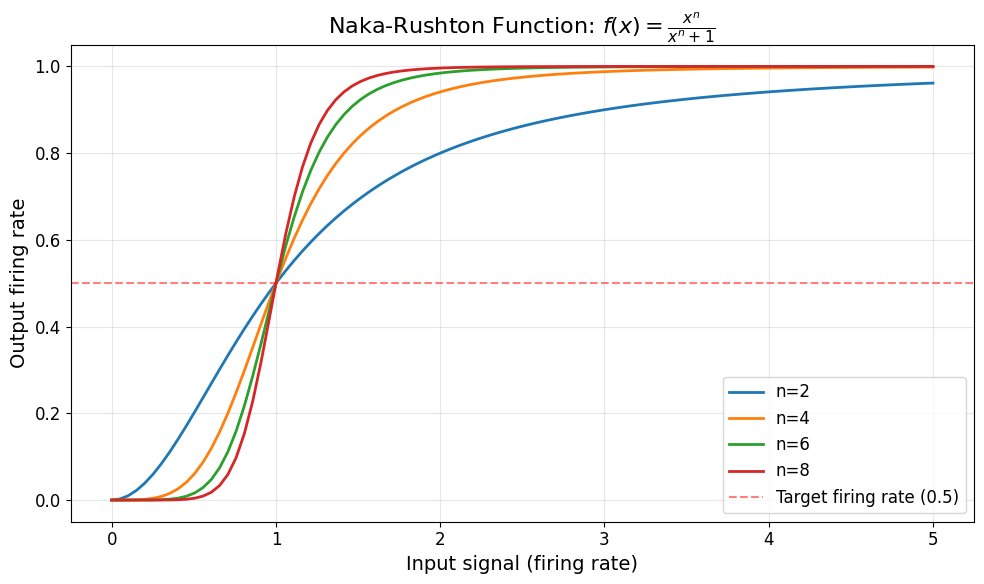

The Naka-Rushton function saturates at 1.0 for large inputs.
For our model, we aim to keep neurons firing around 0.5 to operate in the nonlinear region.


In [6]:
# Visualise the Naka-Rushton function
x_vals = jnp.linspace(0, 5, 100)
n_values = [2, 4, 6, 8]

plt.figure(figsize=(10, 6))
for n in n_values:
    y_vals = nr(x_vals, n=n)
    plt.plot(x_vals, y_vals, label=f'n={n}', linewidth=2)

plt.xlabel('Input signal (firing rate)', fontsize=14)
plt.ylabel('Output firing rate', fontsize=14)
plt.title('Naka-Rushton Function: $f(x) = \\frac{x^n}{x^n + 1}$', fontsize=16)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)
plt.axhline(y=0.5, color='r', linestyle='--', alpha=0.5, label='Target firing rate (0.5)')
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

print("The Naka-Rushton function saturates at 1.0 for large inputs.")
print("For our model, we aim to keep neurons firing around 0.5 to operate in the nonlinear region.")


### Simple Circuit Example

Consider a simple three-neuron circuit where:
- $x$ is the input firing rate
- $y$ is the output of the first neuron after Naka-Rushton: $y = f(w_1 \cdot x)$
- $z$ is the final output: $z = f(w_2 \cdot y)$

where $w_1$ and $w_2$ are synaptic weights representing the strength of connections.


In [8]:
# Simple circuit demo
def simple_circuit(x, w1, n=4):
    """Simple three-neuron circuit: x -> z -> y"""
    z = nr(x, n=n)
    y = nr(w1 * z, n=n)
    return y, z

# example
x_input = 1.0
w1 = 0.5

y_out, z_out = simple_circuit(x_input, w1)

print(f"Input signal: x = {x_input:.2f}")
print(f"After first neuron: z = {z_out:.4f}")
print(f"After second neuron: y = {y_out:.4f}")


Input signal: x = 1.00
After first neuron: z = 0.5000
After second neuron: y = 0.0039


In [10]:
# True circuit
'''
b = nr(w_osn_b * alpha * x)
r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)
g = nr(w_osn_g * alpha * x - w_b_g * b + W_r_g @ r)

y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_m @ g + w_r_y * r)

#=================

gr = nr(w_cor * cortex + w_y * y)
y = y - w_gr_y * gr
'''

'\nb = nr(w_osn_b * alpha * x)\nr = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)\ng = nr(w_osn_g * alpha * x - w_b_g * b + W_r_g @ r)\n\ny = nr(w_osn_y * alpha * x - w_b_y * b - W_g_m @ g + w_r_y * r)\n\n#=================\n\ngr = nr(w_cor * cortex + w_y * y)\ny = y - w_gr_y * gr\n'

## 2. Fixed Point Iteration

In the olfactory bulb circuit, neurons have recurrent connections, creating feedback loops. To find the steady-state firing rates, we need to solve for fixed points where the system reaches equilibrium.

For the green (g) neurons, the fixed point equation is:

g = nr(w_osn_g * alpha * x - w_b_g * [nr(w_osn_b * alpha * x)] + W_r_g @ [nr(w_osn_r * alpha * x - w_b_r * [nr(w_osn_b * alpha * x)] - W_g_r @ g)])

where:
- x is the input odour signal
- alpha is a scaling factor
- w_b is the weight from blue (self-inhibitory) neurons
- W_g_r and W_r_g are weight matrices between green and red neurons
- nr is the Naka-Rushton function

We use **Anderson Acceleration** to efficiently solve this fixed point equation.

In [ ]:
# Demonstrate fixed point iteration for green neurons

# Set up parameters
m = 2  # Number of mitral neurons
x = jnp.ones(m)  # Input odour signal
alpha = jnp.array([1.0, 1.0])  # Scaling factor
W_g_r = jnp.array([[0, 0.1], [0, 0.2]])  # Green to red weight matrix
W_r_g = jnp.array([[0.15, 0], [0.1, 0]])  # Red to green weight matrix
w_osn_g = jnp.array([0.5, 0.5])
w_osn_b = jnp.array([0.5, 0.5])
w_osn_r = jnp.array([0.5, 0.5])
w_osn_y = jnp.array([0.5, 0.5])
w_b_g = jnp.array([0.5, 0.5])
w_b_r = jnp.array([0.5, 0.5])
w_b_y = jnp.array([0.5, 0.5])
w_r_y = jnp.array([0.5, 0.5])


# Initial guess
g0 = jnp.zeros(m)

# Solve using Anderson Acceleration
aa = AndersonAcceleration(mitral_fixed_point, history_size=5, tol=1e-10, maxiter=10)
solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, W_r_g, alpha)
g_fixed = solution.params

print(f"Fixed point solution for green neurons (g):")
print(f"g = {np.array(g_fixed)}")
print(f"\nNumber of iterations: {solution.state.iter_num}")


# Verify it's a fixed point
g_verify = mitral_fixed_point(g_fixed, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, W_r_g, alpha)
print(f"\nVerification (should be close to g):")
print(f"g_new = {np.array(g_verify)}")


Fixed point solution for green neurons (g):
g = [0.04935047 0.04847251]

Number of iterations: 4

Verification (should be close to g):
g_new = [0.04935047 0.04847251]


## 3. Parameter Optimisation

Given known input odour signals and target output firing rates from the mitral cells, we want to find parameter configurations (weights) that produce these outputs.

**Strategy:**
1. Sample initial parameters from parameter space
2. Use gradient descent (Adam optimizer) to minimise the loss function
3. The loss function measures the difference between actual y and target y firing rates
4. Constrain outputs to be positive and approximately 0.5 (operating in nonlinear region)


In [81]:
# Set up optimisation problem
m = 2  # Number of mitral neurons
n_var = 4  # r, g, b, y
n = n_var * m  # Total state length
x = jnp.ones(m)  # Input odour signal

# Target firing rates (all neurons should fire around 0.5)
y_target = jnp.array([0.5, 0.5])  # Mitral cell output
g_target = jnp.array([0.5, 0.5])  # Green neurons
b_target = jnp.array([0.5, 0.5])  # Blue neurons
r_target = jnp.array([0.5, 0.5])  # Red neurons

# Number of parameters in the model
# Parameters: w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y,
#            W_g_r, W_r_g, W_g_m, alpha, w_cor, w_y, w_granule
no_params = 36  # Total number of parameters

print(f"Setup:")
print(f"  - Number of mitral neurons (channels): {m}")
print(f"  - Number of parameters: {no_params}")
print(f"  - Target firing rates: {np.array(y_target)}")
print(f"  - Input signal: {np.array(x)}")


Setup:
  - Number of mitral neurons (channels): 2
  - Number of parameters: 36
  - Target firing rates: [0.5 0.5]
  - Input signal: [1. 1.]


In [ ]:
# Define loss function
def loss_fn(theta):
    """Loss function: sum of squared differences from target firing rates"""
    g, b, r, y = mitral_output(theta, x, m)
    loss = (jnp.sum((y - y_target) ** 2) +
            jnp.sum((g - g_target) ** 2) +
            jnp.sum((b - b_target) ** 2) +
            jnp.sum((r - r_target) ** 2))
    return loss

# Gradient descent optimiser
def gradient_descent(loss_fn, theta_init, lr=0.01, steps=200, record_every=20):
    """
    Fast gradient descent optimizer with JIT-compiled inner loop

    Performance improvements:
    - JIT-compiled optimization step (faster execution)
    - Uses JAX's fori_loop for compiled iteration (no Python overhead)
    - Reduced loss evaluations (only when needed for history)
    """
    # JIT compile the gradient function
    grad_fn = jax.jit(jax.grad(loss_fn))

    # JIT compile a single optimization step
    @jax.jit
    def step_fn(theta):
        g = grad_fn(theta)
        theta_new = theta - lr * g
        theta_new = jnp.clip(theta_new, 0.0, None)  # Keep weights non-negative
        return theta_new

    # Use JAX's fori_loop for fast compiled iteration (much faster than Python loop)
    def body_fn(step, theta):
        return step_fn(theta)

    # Run the compiled loop - this is much faster than Python for loop
    theta = jax.lax.fori_loop(0, steps, body_fn, theta_init)

    # Record loss history (simplified - compute only when needed)
    loss_history = []
    if record_every > 0:
        loss_fn_jit = jax.jit(loss_fn)
        # Record initial loss
        loss_history.append(float(loss_fn_jit(theta_init)))
        # Record loss at intervals (recompute theta for those steps)
        for step in range(record_every, steps, record_every):
            theta_temp = theta_init
            for s in range(step):
                theta_temp = step_fn(theta_temp)
            loss_history.append(float(loss_fn_jit(theta_temp)))
        # Record final loss
        loss_history.append(float(loss_fn_jit(theta)))

    return theta, loss_history


In [ ]:
import torch
import torch.optim as optim

def adam_optimiser(loss_fn, theta_init, lr=0.005, steps=300, beta1=0.9, beta2=0.999, eps=1e-8,
                   lr_decay=0.95, patience=50, min_delta=1e-6):
    """
    Optimized Adam optimizer using PyTorch's built-in optimizer with JAX JIT compilation

    This function wraps PyTorch's Adam optimizer to work with JAX loss functions.
    JAX operations are JIT-compiled for maximum performance.

    """
    # JIT compile both gradient and loss functions for speed
    grad_fn = jax.jit(jax.grad(loss_fn))
    loss_fn_jit = jax.jit(loss_fn)

    # Pre-compile functions on first call to avoid compilation overhead during loop
    _ = grad_fn(theta_init)
    _ = loss_fn_jit(theta_init)

    # Convert JAX array to PyTorch tensor for optimizer (only once)
    theta_init_np = np.array(theta_init)
    theta_torch = torch.tensor(theta_init_np, dtype=torch.float32, requires_grad=True)

    # Create Adam optimizer with PyTorch
    optimizer = optim.Adam([theta_torch], lr=lr, betas=(beta1, beta2), eps=eps)

    # Learning rate scheduler for decay
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=lr_decay, patience=patience,
        min_lr=lr * 0.01, threshold=min_delta
    )

    loss_history = []
    best_loss = float('inf')
    current_lr = lr

    for step in range(steps):
        # Convert PyTorch tensor to numpy (faster than going through JAX first)
        theta_torch_np = theta_torch.detach().cpu().numpy()
        theta_jax = jnp.array(theta_torch_np)

        # Compute gradient using JIT-compiled JAX function
        grad_jax = grad_fn(theta_jax)

        # Convert gradient to PyTorch tensor (use numpy for faster conversion)
        grad_np = np.array(grad_jax)
        grad_torch = torch.tensor(grad_np, dtype=torch.float32)

        # Set gradients manually for PyTorch optimizer
        theta_torch.grad = grad_torch

        # Update parameters using PyTorch's Adam
        optimizer.step()

        # Keep weights non-negative
        with torch.no_grad():
            theta_torch.clamp_(min=0.0)

        # Compute loss for monitoring and scheduling (only when needed)
        if step % 10 == 0 or step == steps - 1:
            theta_jax = jnp.array(theta_torch.detach().cpu().numpy())
            loss_float = float(loss_fn_jit(theta_jax))  # Use JIT-compiled loss

            # Update learning rate scheduler
            scheduler.step(loss_float)
            current_lr = optimizer.param_groups[0]['lr']

            # Record loss
            loss_history.append(loss_float)

            # Check for improvement
            if loss_float < best_loss - min_delta:
                best_loss = loss_float

    # Convert back to JAX array (final conversion)
    theta_optimized = jnp.array(theta_torch.detach().cpu().numpy())

    return theta_optimized, loss_history

In [129]:
# Sample initial parameters
no_samples = 10  # Number of different starting points
key = jax.random.PRNGKey(0)
theta_matrix = jax.random.uniform(key, (no_samples, no_params), minval=0.0, maxval=2.0)

#for all the matrices weights , set the diagonal to 0
for i in range(no_samples):
    theta_matrix = theta_matrix.at[0, -2].set(0)
    theta_matrix = theta_matrix.at[0, -4].set(0)
    theta_matrix = theta_matrix.at[0, -6].set(0)
    theta_matrix = theta_matrix.at[0, -8].set(0)

print(f"Sampled {no_samples} initial parameter sets")
print(f"Initial parameter matrix shape: {theta_matrix.shape}")

Sampled 10 initial parameter sets
Initial parameter matrix shape: (10, 36)


In [142]:
# Run optimisation for each sample
theta_opt = jnp.zeros((no_samples, no_params))
y_opt = jnp.zeros((no_samples, m))
g_opt = jnp.zeros((no_samples, m))
b_opt = jnp.zeros((no_samples, m))
r_opt = jnp.zeros((no_samples, m))
all_loss_histories = []

print("Running gradient descent optimisation...\n")

for i in range(no_samples):
    print(f"Sample {i+1}/{no_samples}:")
    theta_init = theta_matrix[i, :]
    initial_loss = loss_fn(theta_init)
    print(f"  Initial loss: {initial_loss:.6f}")

    theta_optimised, loss_history = gradient_descent(
        loss_fn, theta_init, lr=0.08, steps=600
    )
    all_loss_histories.append(loss_history)

    theta_opt = theta_opt.at[i, :].set(theta_optimised)
    g, b, r, y = mitral_output(theta_optimised, x, m)

    y_opt = y_opt.at[i, :].set(y)
    g_opt = g_opt.at[i, :].set(g)
    b_opt = b_opt.at[i, :].set(b)
    r_opt = r_opt.at[i, :].set(r)

    final_loss = loss_fn(theta_optimised)
    print(f"  Final loss: {final_loss:.6f}")
    print(f"  Output y: {np.array(y)}")
    print()


Running gradient descent optimisation...

Sample 1/10:
  Initial loss: 1.396412
  Final loss: 0.110499
  Output y: [0.5916159  0.60507053]

Sample 2/10:
  Initial loss: 1.016363
  Final loss: 0.151093
  Output y: [0.55033183 0.6635711 ]

Sample 3/10:
  Initial loss: 1.023738
  Final loss: 0.000000
  Output y: [0.50000954 0.4999801 ]

Sample 4/10:
  Initial loss: 1.454578
  Final loss: 0.113589
  Output y: [0.6736072  0.52009314]

Sample 5/10:
  Initial loss: 1.167718
  Final loss: 0.005739
  Output y: [0.44946516 0.47577584]

Sample 6/10:
  Initial loss: 1.625204
  Final loss: 0.018712
  Output y: [0.41780692 0.42542228]

Sample 7/10:
  Initial loss: 1.610826
  Final loss: 0.037527
  Output y: [0.3961637  0.47679278]

Sample 8/10:
  Initial loss: 1.313898
  Final loss: 0.001451
  Output y: [0.47921127 0.48729563]

Sample 9/10:
  Initial loss: 1.929365
  Final loss: 0.300290
  Output y: [0.5072829 0.5815677]

Sample 10/10:
  Initial loss: 1.455510
  Final loss: 0.024097
  Output y: [0.4

In [136]:

# Run optimisation for each sample
theta_opt = jnp.zeros((no_samples, no_params))
y_opt = jnp.zeros((no_samples, m))
g_opt = jnp.zeros((no_samples, m))
b_opt = jnp.zeros((no_samples, m))
r_opt = jnp.zeros((no_samples, m))
all_loss_histories = []

print("Running Adam optimizer...\n")

for i in range(no_samples):
    print(f"Sample {i+1}/{no_samples}:")
    theta_init = theta_matrix[i, :]
    initial_loss = loss_fn(theta_init)
    print(f"  Initial loss: {initial_loss:.6f}")

    theta_optimised, loss_history = adam_optimiser(
        loss_fn, theta_init, lr=0.001, steps=500
    )
    all_loss_histories.append(loss_history)

    theta_opt = theta_opt.at[i, :].set(theta_optimised)
    g, b, r, y = mitral_output(theta_optimised, x, m)

    y_opt = y_opt.at[i, :].set(y)
    g_opt = g_opt.at[i, :].set(g)
    b_opt = b_opt.at[i, :].set(b)
    r_opt = r_opt.at[i, :].set(r)

    final_loss = loss_fn(theta_optimised)
    print(f"  Final loss: {final_loss:.6f}")
    print(f"  Output y: {np.array(y)}")
    print()

Running Adam optimizer...

Sample 1/10:
  Initial loss: 1.396412
  Final loss: 0.510994
  Output y: [5.0853837e-01 7.0525231e-11]

Sample 2/10:
  Initial loss: 1.016363
  Final loss: 0.298810
  Output y: [0.5648093  0.46690363]

Sample 3/10:
  Initial loss: 1.023738
  Final loss: 0.344806
  Output y: [0.50429505 0.49032375]

Sample 4/10:
  Initial loss: 1.454578
  Final loss: 0.207806
  Output y: [0.4833692  0.46231818]

Sample 5/10:
  Initial loss: 1.167718
  Final loss: 0.091905
  Output y: [0.4730974  0.47127628]

Sample 6/10:
  Initial loss: 1.625204
  Final loss: 0.322308
  Output y: [0.512934   0.29766455]

Sample 7/10:
  Initial loss: 1.610826
  Final loss: 0.763534
  Output y: [0.37426835 0.6114247 ]

Sample 8/10:
  Initial loss: 1.313898
  Final loss: 0.427308
  Output y: [0.45440307 0.48720193]

Sample 9/10:
  Initial loss: 1.929365
  Final loss: 0.620276
  Output y: [0.46323854 0.49126408]

Sample 10/10:
  Initial loss: 1.455510
  Final loss: 0.080781
  Output y: [0.4807566 

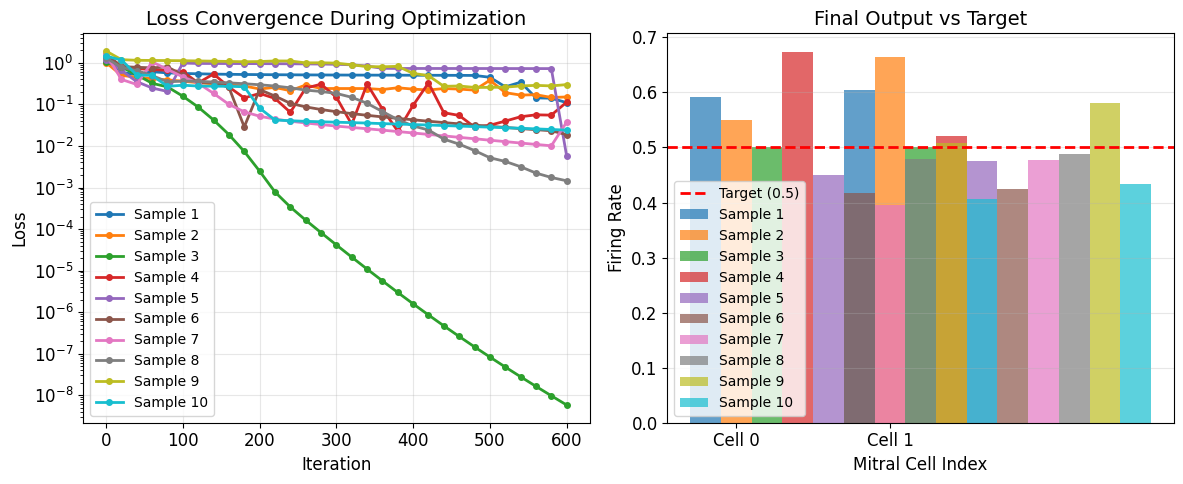

Optimization results:
Target output: [0.5 0.5]

Optimized outputs:
  Sample 1: y = [0.5916159  0.60507053]
  Sample 2: y = [0.55033183 0.6635711 ]
  Sample 3: y = [0.50000954 0.4999801 ]
  Sample 4: y = [0.6736072  0.52009314]
  Sample 5: y = [0.44946516 0.47577584]
  Sample 6: y = [0.41780692 0.42542228]
  Sample 7: y = [0.3961637  0.47679278]
  Sample 8: y = [0.47921127 0.48729563]
  Sample 9: y = [0.5072829 0.5815677]
  Sample 10: y = [0.40653774 0.43412802]


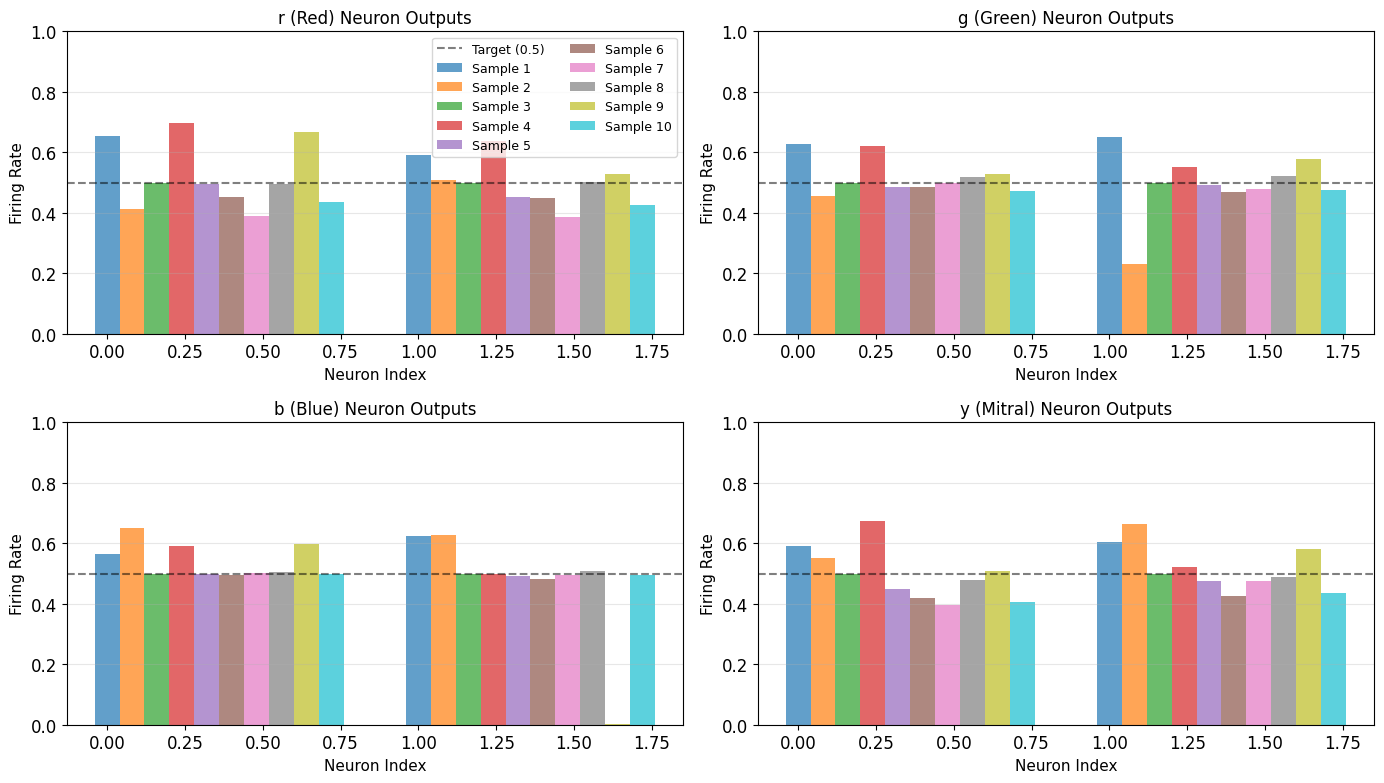


Summary of neuron outputs:

r (Red):
  Mean: 0.5088
  Std:  0.0911
  Min:  0.3849
  Max:  0.6968
  Target distance: 0.0695

g (Green):
  Mean: 0.5071
  Std:  0.0844
  Min:  0.2295
  Max:  0.6515
  Target distance: 0.0530

b (Blue):
  Mean: 0.5060
  Std:  0.1274
  Min:  0.0011
  Max:  0.6521
  Target distance: 0.0607

y (Mitral):
  Mean: 0.5071
  Std:  0.0792
  Min:  0.3962
  Max:  0.6736
  Target distance: 0.0622
  Sample 10: y = [0.40653774 0.43412802]


In [143]:
# Visualise optimisation convergence
plt.figure(figsize=(12, 5))

# Plot 1: Loss convergence
plt.subplot(1, 2, 1)
for i, loss_hist in enumerate(all_loss_histories):
    steps = np.arange(0, len(loss_hist)) * 20
    plt.plot(steps, loss_hist, 'o-', label=f'Sample {i+1}', linewidth=2, markersize=4)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.title('Loss Convergence During Optimization', fontsize=14)
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)

# Plot 2: Final outputs vs targets
plt.subplot(1, 2, 2)
x_pos = np.arange(m)
width = 0.2

for i in range(no_samples):
    plt.bar(x_pos + i*width, y_opt[i], width, label=f'Sample {i+1}', alpha=0.7)

plt.axhline(y=0.5, color='r', linestyle='--', linewidth=2, label='Target (0.5)')
plt.xlabel('Mitral Cell Index', fontsize=12)
plt.ylabel('Firing Rate', fontsize=12)
plt.title('Final Output vs Target', fontsize=14)
plt.xticks(x_pos + width, [f'Cell {j}' for j in range(m)])
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("Optimization results:")
print(f"Target output: {np.array(y_target)}")
print(f"\nOptimized outputs:")
for i in range(no_samples):
    print(f"  Sample {i+1}: y = {np.array(y_opt[i])}")

##########################
# Plot the output values of r, g, b, y for all samples
plt.figure(figsize=(14, 8))

# Create subplots for each neuron type
neuron_types = ['r (Red)', 'g (Green)', 'b (Blue)', 'y (Mitral)']
outputs = [r_opt, g_opt, b_opt, y_opt]
colors = ['red', 'green', 'blue', 'orange']

for idx, (neuron_type, output, color) in enumerate(zip(neuron_types, outputs, colors)):
    plt.subplot(2, 2, idx + 1)

    x_pos = np.arange(m)
    width = 0.8 / no_samples

    # Plot bars for each sample
    for i in range(no_samples):
        plt.bar(x_pos + i*width, np.array(output[i]), width,
                label=f'Sample {i+1}' if idx == 0 else '', alpha=0.7)

    # Add target line at 0.5
    plt.axhline(y=0.5, color='black', linestyle='--', linewidth=1.5,
                alpha=0.5, label='Target (0.5)')

    plt.xlabel('Neuron Index', fontsize=11)
    plt.ylabel('Firing Rate', fontsize=11)
    plt.title(f'{neuron_type} Neuron Outputs', fontsize=12)
    plt.ylim([0, 1.0])
    plt.grid(True, alpha=0.3, axis='y')

    if idx == 0:
        plt.legend(fontsize=9, ncol=2)

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nSummary of neuron outputs:")
print("=" * 60)
for neuron_type, output in zip(neuron_types, outputs):
    output_array = np.array(output)
    print(f"\n{neuron_type}:")
    print(f"  Mean: {output_array.mean():.4f}")
    print(f"  Std:  {output_array.std():.4f}")
    print(f"  Min:  {output_array.min():.4f}")
    print(f"  Max:  {output_array.max():.4f}")
    print(f"  Target distance: {np.abs(output_array - 0.5).mean():.4f}")



print(f"  Sample {i+1}: y = {np.array(y_opt[i])}")


Stability


With realistic theta, find delta theta
